# Baseline Regression

## Load the cleaned dataset and split chronologically

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

# Set plotting defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

# Locate the project directory
PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "mmm_eda_clean.csv").exists():
    if (PROJECT_DIR.parent / "data" / "mmm_eda_clean.csv").exists():
        PROJECT_DIR = PROJECT_DIR.parent

DATA_PATH = PROJECT_DIR / "data" / "mmm_eda_clean.csv"

# Confirm that the cleaned dataset exists
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cannot find the cleaned dataset at: {DATA_PATH}"
    )

In [2]:
# Load and sort the data
df = pd.read_csv(DATA_PATH, parse_dates=["DATE"])
df = df.sort_values("DATE").reset_index(drop=True)

# Define the target and media channels
target_col = "revenue"

media_cols = [
    "tv_S",
    "ooh_S",
    "print_S",
    "facebook_S",
    "search_S"
]

In [3]:
# Add month as a categorical seasonal control
df["month"] = df["DATE"].dt.month.astype(str)

# Use the first 80% for training and the final 20% for testing
split_idx = int(len(df) * 0.80)

train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

In [4]:
# Display split details
print("Dataset loaded successfully.")
print("Full dataset shape:", df.shape)
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print(
    "\nTraining period:",
    train_df["DATE"].min().date(),
    "to",
    train_df["DATE"].max().date()
)

print(
    "Testing period:",
    test_df["DATE"].min().date(),
    "to",
    test_df["DATE"].max().date()
)

print("\nMedia channels:", media_cols)
print("Target variable:", target_col)

# Verify that training dates precede testing dates
assert train_df["DATE"].max() < test_df["DATE"].min()

print("\nChronological split verified.")

Dataset loaded successfully.
Full dataset shape: (208, 13)
Training observations: 166
Testing observations: 42

Training period: 2015-11-23 to 2019-01-21
Testing period: 2019-01-28 to 2019-11-11

Media channels: ['tv_S', 'ooh_S', 'print_S', 'facebook_S', 'search_S']
Target variable: revenue

Chronological split verified.


## Build and fit the baseline Ridge regression

In [5]:
# Separate numerical media features and categorical seasonal controls
numeric_features = media_cols
categorical_features = ["month"]

# Preprocess numerical and categorical predictors
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

# Create a modeling pipeline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

In [6]:
# Select predictors and target
X_train = train_df[numeric_features + categorical_features]
y_train = train_df[target_col]

X_test = test_df[numeric_features + categorical_features]
y_test = test_df[target_col]

# Fit using training data only
baseline_model.fit(X_train, y_train)

# Generate predictions for training and test periods
train_pred = baseline_model.predict(X_train)
test_pred = baseline_model.predict(X_test)

print("Baseline Ridge regression fitted successfully.")
print("Training predictions:", len(train_pred))
print("Testing predictions:", len(test_pred))

Baseline Ridge regression fitted successfully.
Training predictions: 166
Testing predictions: 42


## Evaluate model performance

In [7]:
def calculate_metrics(y_true, y_pred):
    """Calculate regression metrics for model evaluation."""

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    # Revenue is positive, so MAPE is defined for this dataset
    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

    # Normalize RMSE by the observed target range
    revenue_range = np.max(y_true) - np.min(y_true)
    nrmse = rmse / revenue_range if revenue_range > 0 else np.nan

    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse,
        "MAPE (%)": mape,
        "NRMSE (range)": nrmse
    }

In [8]:
# Evaluate training and holdout predictions
train_metrics = calculate_metrics(y_train, train_pred)
test_metrics = calculate_metrics(y_test, test_pred)

metrics_df = pd.DataFrame({
    "Training": train_metrics,
    "Holdout": test_metrics
})

print("Baseline regression performance:")
display(metrics_df.round(4))

Baseline regression performance:


,Training,Holdout
R2,0.7195,0.5997
MAE,300433.1406,351882.6900
RMSE,380915.9285,412914.7812
MAPE (%),19.5024,30.6075
NRMSE (range),0.1229,0.1970


## Plot actual vs. predicted revenue

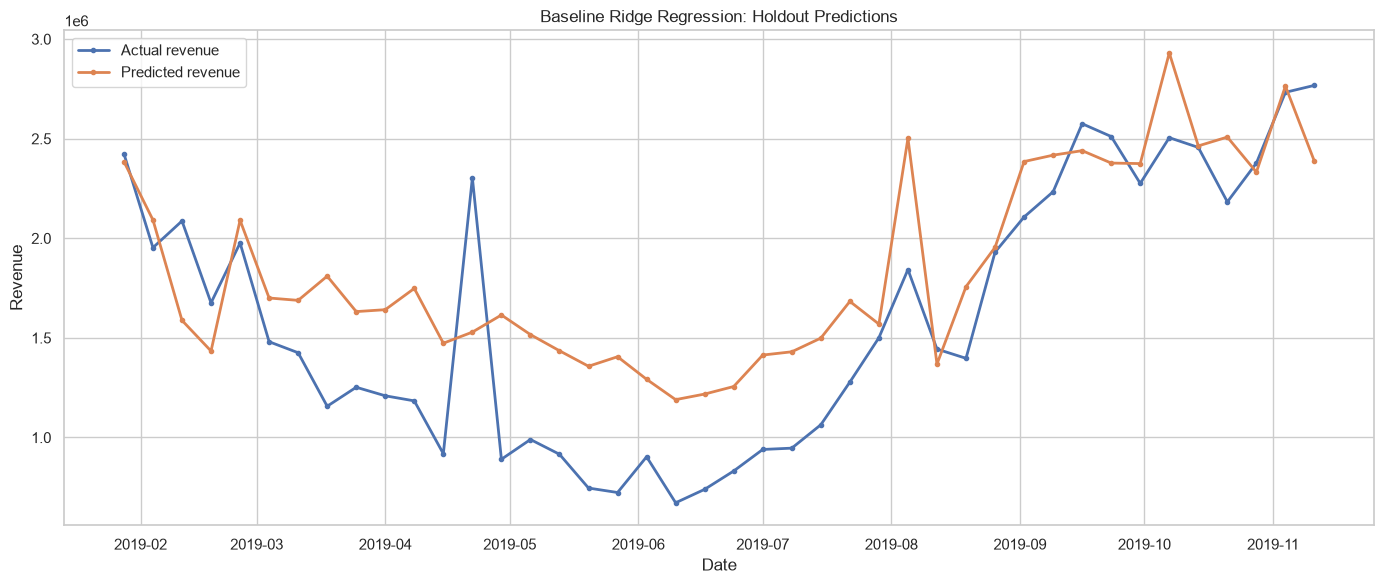

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(
    test_df["DATE"],
    y_test.to_numpy(),
    label="Actual revenue",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.plot(
    test_df["DATE"],
    test_pred,
    label="Predicted revenue",
    linewidth=2,
    marker="o",
    markersize=3
)

plt.title("Baseline Ridge Regression: Holdout Predictions")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.tight_layout()
plt.show()

## Inspecting prediction errors

In [10]:
holdout_results = pd.DataFrame({
    "DATE": test_df["DATE"].to_numpy(),
    "Actual_Revenue": y_test.to_numpy(),
    "Predicted_Revenue": test_pred
})

holdout_results["Error"] = (
    holdout_results["Actual_Revenue"]
    - holdout_results["Predicted_Revenue"]
)

holdout_results["Absolute_Percentage_Error"] = (
    holdout_results["Error"].abs()
    / holdout_results["Actual_Revenue"]
    * 100
)

display(holdout_results.head(10).round(2))

print(
    "\nLargest absolute errors:"
)

display(
    holdout_results.nlargest(5, "Absolute_Percentage_Error")
    .round(2)
)

C:\Users\Neel\AppData\Local\Temp\ipykernel_5312\2741038671.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(holdout_results.head(10).round(2))


,DATE,Actual_Revenue,Predicted_Revenue,Error,Absolute_Percentage_Error
0,2019-01-28,2424486.67,2385055.00,39431.67,1.63
1,2019-02-04,1953060.00,2092102.06,-139042.06,7.12
2,2019-02-11,2086935.00,1587943.48,498991.52,23.91
3,2019-02-18,1675816.67,1434046.77,241769.90,14.43
4,2019-02-25,1976413.33,2090610.44,-114197.11,5.78
5,2019-03-04,1480760.00,1700279.71,-219519.71,14.82
6,2019-03-11,1425500.00,1688409.62,-262909.62,18.44
7,2019-03-18,1156860.00,1810010.53,-653150.53,56.46
8,2019-03-25,1252230.00,1632029.76,-379799.76,30.33
9,2019-04-01,1209373.33,1641629.69,-432256.35,35.74



Largest absolute errors:


C:\Users\Neel\AppData\Local\Temp\ipykernel_5312\2741038671.py:26: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(2)


,DATE,Actual_Revenue,Predicted_Revenue,Error,Absolute_Percentage_Error
17,2019-05-27,723785.00,1405403.86,-681618.86,94.17
16,2019-05-20,746205.00,1357676.94,-611471.94,81.94
13,2019-04-29,890675.00,1614966.85,-724291.85,81.32
19,2019-06-10,672250.00,1190002.66,-517752.66,77.02
20,2019-06-17,739783.33,1218091.58,-478308.24,64.66



### Stage 2: Baseline Regression Modeling

1. Established a baseline Ridge regression model using the five raw media-spend variables and month indicators to account for seasonality. Applied median imputation, feature scaling for numerical media variables, and one-hot encoding for the categorical month feature.

2. Used a chronological train-test split to avoid training on future observations: **166 training weeks** and **42 holdout weeks**. The baseline model achieved training R² of 0.7195 and holdout R² of **0.5997**, with holdout MAE of approximately 351,883, RMSE of 412,915, and MAPE of 30.61%.

3. Examined actual-versus-predicted revenue and holdout errors. The model struggled to capture the sustained revenue decline during April–June 2019, substantially overpredicting revenue in several weeks. These limitations motivated the more advanced MMM in Stage 3, which incorporated adstock, saturation, and a competitor-sales control variable.
